# Task 1 Hadoop Cluster Setup and Fault Tolerance

This notebook follows the Task 1 sequence in my Word working documentation.
It explains how I started the cluster, checked HDFS and YARN, uploaded data,
submitted a test job and demonstrated recovery after stopping one DataNode.

I repeated the work in a new folder after Progress Update 1 to improve my
understanding. GitHub was an optional way to track changes and practise branches
and commits. The [debugging journal](../debugging_journal.md) records the issues.

**Evidence note:** screenshots and quoted results below are from the completed
work. Python cells are provided for reproduction and are saved unexecuted;
they are not presented as the source of those historical screenshots.

## 1 Project Files and Notebook Controls

I copied docker-compose.yml, configs/ and userfiles/ into the final project.
Docker Desktop must be running to execute live commands. The raw CSVs belong in
userfiles/ca1-data/, which is shared with the client as /home/user/ca1-data/.

Run this notebook with a local Python 3 kernel from the project or notebooks/
folder. Set **RUN_LIVE = True** only when you want to run Docker commands.
The controlled fault test has a separate switch and is skipped by default.
Live recheck logs go to evidence/notebook-recheck/; the original reports remain
the historical evidence linked below.

In [ ]:
from pathlib import Path
import subprocess
import json
import re

ROOT = Path.cwd()
if not (ROOT / "docker-compose.yml").exists():
    ROOT = ROOT.parent
assert (ROOT / "docker-compose.yml").exists(), "Open this notebook from the project folder."

RUN_LIVE = False
RUN_FAULT_TEST = False
TARGET_DATANODE = ""  # Choose a current replica holder after the location check.


def run_command(args, save_as=None):
    """Run commands from the project folder when live execution is enabled."""
    print("Command:", subprocess.list2cmdline(args))
    if not RUN_LIVE:
        print("Not executed: RUN_LIVE is False.")
        return ""
    result = subprocess.run(args, cwd=ROOT, capture_output=True,
                            text=True, encoding="utf-8", errors="replace")
    output = result.stdout + result.stderr
    print(output)
    if save_as:
        folder = ROOT / "evidence" / "notebook-recheck"
        folder.mkdir(parents=True, exist_ok=True)
        (folder / save_as).write_text(output, encoding="utf-8")
    if result.returncode:
        raise RuntimeError(f"Command exited with code {result.returncode}")
    return output


def client(*args, save_as=None):
    return run_command(["docker", "compose", "exec", "-T", "client", *args], save_as)

print("Project:", ROOT.name)
print("Live commands enabled:", RUN_LIVE)

## 2 Cluster Design and Configuration

| Service | Number | Purpose |
|---|---:|---|
| NameNode | 1 | Tracks HDFS filenames, blocks and replica locations |
| DataNode | 3 | Stores the block replicas |
| ResourceManager | 1 | Schedules YARN applications and allocates resources |
| NodeManager | 1 | Runs application/task containers on the worker |
| Client | 1 | Runs HDFS commands and submits Python mrjob jobs |

The client asks the NameNode for block locations, then transfers data to or from
DataNodes. For MapReduce, it submits work to YARN; the NodeManager runs the
allocated containers.

| Choice | Reason |
|---|---|
| Replication factor 2 | Keeps a second block copy on another DataNode |
| Three DataNodes | Provides a third location for a replacement replica during an outage |
| 4 MiB blocks | Splits the larger CSVs into inspectable blocks |
| Separate persistent storage folders | Retains NameNode metadata and each DataNode's blocks across container recreation |
| Read-only configuration mounts | Keeps configuration managed through the project files |
| Ports 9870 and 8088 | Exposes the HDFS and YARN web interfaces |

The [Compose file](../docker-compose.yml) defines startup. Detailed explanations
of non-default settings are in [config_justification.md](../config_justification.md).

## 3 Start All Seven Services

`docker compose up -d` starts the services in the background. `ps -a` also
reveals containers that exited, so seven created containers alone are not proof
of a healthy cluster. My recorded output showed all seven services started.

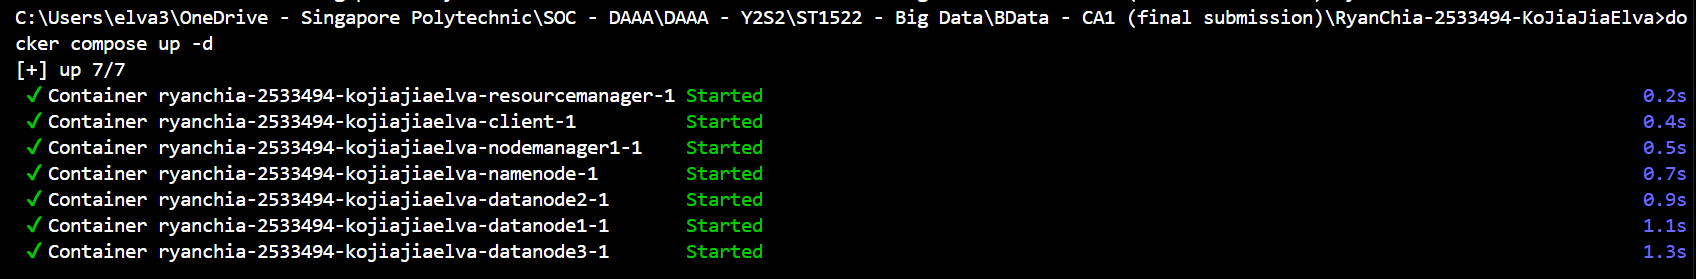

In [ ]:
run_command(["docker", "compose", "up", "-d"])
run_command(["docker", "compose", "ps", "-a"])

## 4 Verify HDFS and YARN Before Uploading

I opened the NameNode UI at http://localhost:9870 and checked for three live
DataNodes. I also ran dfsadmin -report to check their registration and HDFS health.
The screenshot below was taken before upload, which explains its zero blocks.

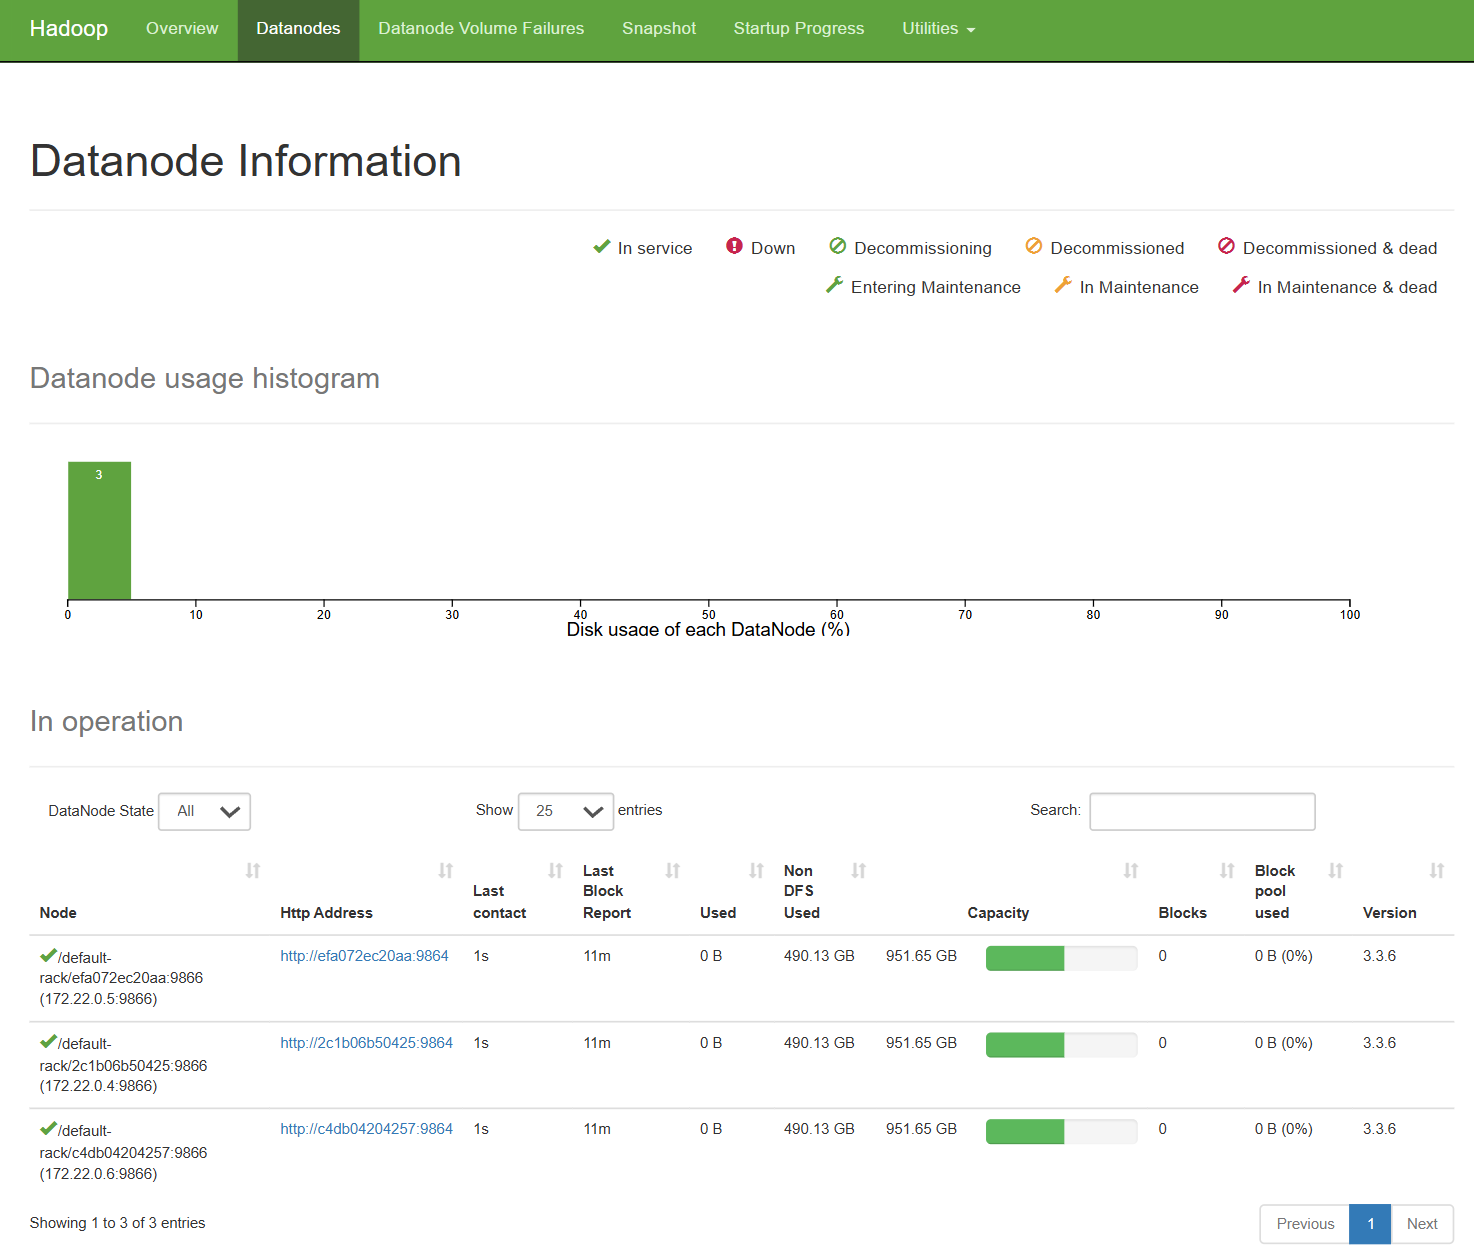

In [ ]:
client("hdfs", "dfsadmin", "-report", save_as="dfsadmin-before.txt")
client("yarn", "node", "-list", save_as="yarn-nodes.txt")

The recorded YARN check showed **one RUNNING NodeManager**. This is expected:
three DataNodes provide HDFS storage, while one NodeManager provides YARN compute.
The deprecation warning about YARN_CONF_DIR did not prevent the connection.
The ResourceManager UI is available at http://localhost:8088.

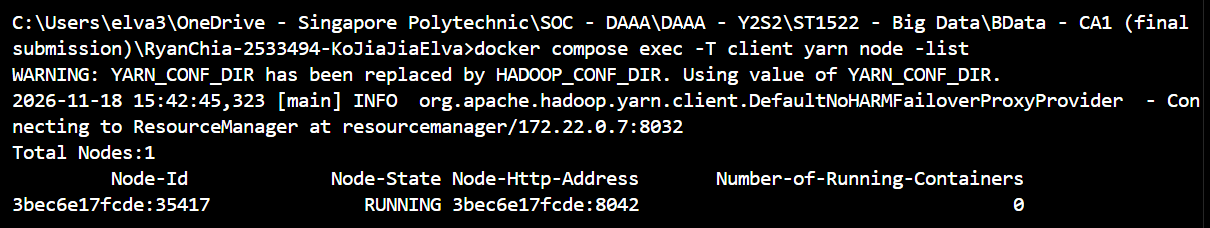

## 5 Upload the Raw CSVs and Read Them from HDFS

Files in VS Code are local files, not automatically HDFS files. I created
/sg_mobility/raw/, uploaded the four original CSVs from the client mount, then
listed the same directory in the terminal and HDFS browser.

| Raw file | Size in bytes |
|---|---:|
| bus_stops.csv | 357,464 |
| origin_destination_bus_202609.csv | 239,594,439 |
| rainfall_20260901_20260930.csv | 51,584,840 |
| carpark_20260901_20260930.csv | 105,658,614 |

The cell uses -put -f for repeatable uploads of these retained files. The head
command reads the beginning of the HDFS file, checking client read access.

In [ ]:
raw_files = sorted((ROOT / "userfiles" / "ca1-data").glob("*.csv"))
if RUN_LIVE:
    assert len(raw_files) == 4, "Expected the four original raw CSV files."
    client("hdfs", "dfs", "-mkdir", "-p", "/sg_mobility/raw")
    container_paths = ["/home/user/ca1-data/" + path.name for path in raw_files]
    client("hdfs", "dfs", "-put", "-f", *container_paths, "/sg_mobility/raw/")
client("hdfs", "dfs", "-ls", "/sg_mobility/raw", save_as="raw-files.txt")
client("hdfs", "dfs", "-head", "/sg_mobility/raw/bus_stops.csv")

## 6 Submit a Small mrjob Test to YARN

count_bus_stop_records.py skips the raw CSV header, emits a count of one per
record, then sums those values. The expected result is **5,209 data records**.
This tests HDFS input access and YARN job submission; it is separate from M1-M4.

mrjob must be installed in the client Python environment. If the import check
fails during reproduction, install version 0.7.4 as shown below.

In [ ]:
client("python3", "-c", "import mrjob; print(mrjob.__version__)")
# If the import fails, run this once, then rerun the check:
# client("python3", "-m", "pip", "install", "mrjob==0.7.4")
client("python3", "count_bus_stop_records.py", "-r", "hadoop",
       "hdfs:///sg_mobility/raw/bus_stops.csv", save_as="bus-stop-test.txt")

The original final-project test application
**application_1795002805512_0001** finished with **SUCCEEDED**. A new execution
will receive a new application ID.

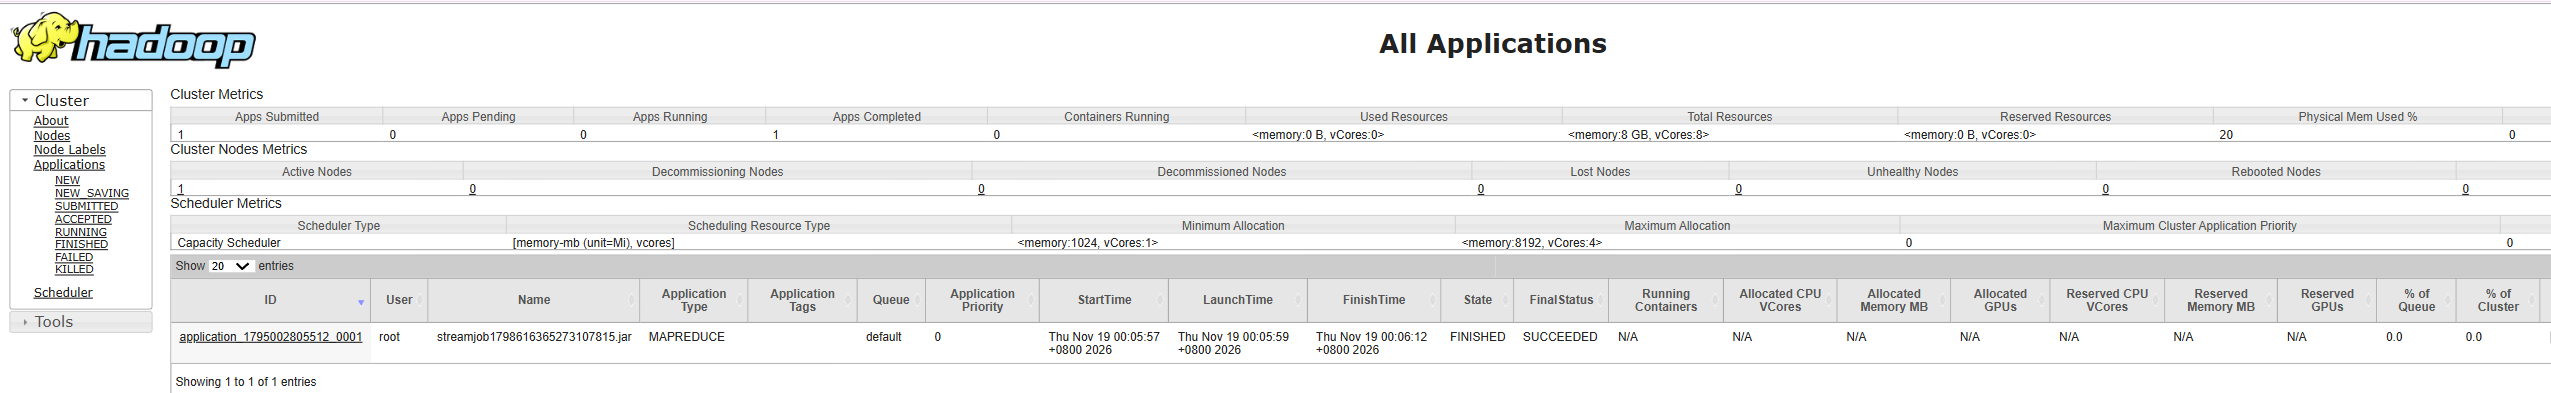

## 7 Check Blocks, Replication and Distribution

I ran `hdfs fsck /sg_mobility/ -files -blocks -locations` after uploading the four
raw CSVs. It checks file health and reports every block's replica locations.
The saved report contains the historical four-file checkpoint; a live check now
also includes canonical, quarantine and metadata files added later.

[Original complete report](../evidence/fault-tolerance-demo/hdfs-fsck.txt)

In [ ]:
client("hdfs", "fsck", "/sg_mobility/", "-files", "-blocks", "-locations",
       save_as="hdfs-fsck-current.txt")

### Recorded Result and Explanation

```text
Status: HEALTHY
 Number of data-nodes:	3
 Total files:	4
 Total blocks (validated):	98 (avg. block size 4053013 B)
 Under-replicated blocks:	0 (0.0 %)
 Average block replication:	2.0
 Missing blocks:		0
 Corrupt blocks:		0
 Total files:	0
```

HDFS validated **98 logical blocks across four files**, with average replication
2.0 and no missing, corrupt or under-replicated blocks. The saved block-location
lines show the following replica placements:

| DataNode in the original run | Address | Stored block replicas |
|---|---|---:|
| datanode1 | 172.22.0.5 | 69 |
| datanode2 | 172.22.0.4 | 60 |
| datanode3 | 172.22.0.6 | 67 |

The total is **196 placements = 98 blocks x 2 replicas**. HDFS distributed copies
across all three DataNodes; placement need not be perfectly even. Each block had
two copies on different nodes, rather than every file being copied to all three.
IP addresses are historical and can change after recreating containers.

## 8 Identify the Replica Holder Before the Controlled Test

I used raw bus_stops.csv because it occupies one block. The
[before report](../evidence/fault-tolerance-demo/replication-before.txt) showed
two live replicas: 172.22.0.4:9866 and 172.22.0.6:9866. My Docker network check
mapped them to datanode2 and datanode3.

Docker's `/16` describes the subnet; HDFS's `:9866` is the DataNode data-transfer
port. I matched the IP part, not those suffixes.

For a new test, check current addresses rather than assuming the historical
placements still apply. The cell prints the current file locations and each
DataNode container's IP address.

In [ ]:
baseline = client("hdfs", "fsck", "/sg_mobility/raw/bus_stops.csv",
                  "-files", "-blocks", "-locations", save_as="replication-before.txt")
replica_ips = set(re.findall(r"DatanodeInfoWithStorage\[([0-9.]+):", baseline))
replica_services = []
if RUN_LIVE:
    for service in ("datanode1", "datanode2", "datanode3"):
        container_id = subprocess.check_output(
            ["docker", "compose", "ps", "-q", service], cwd=ROOT,
            text=True).strip()
        details = json.loads(subprocess.check_output(
            ["docker", "inspect", container_id], cwd=ROOT, text=True))[0]
        ips = [network["IPAddress"] for network in details["NetworkSettings"]["Networks"].values()]
        print(service, ips)
        if replica_ips.intersection(ips):
            replica_services.append(service)
    print("Current replica holders:", replica_services)

## 9 Controlled Failure, Read Check and Re-replication

This was a deliberate fault test. In my recorded run I stopped **datanode2**,
checked that the file remained readable, waited for HDFS to replace its replica,
then restarted the stopped node. I did not delete its storage or reformat HDFS.

For reproduction, set RUN_LIVE and RUN_FAULT_TEST to True in the controls cell,
then set TARGET_DATANODE to a service identified in the current replica check.
Run the stop, read/recovery and restart cells in that order. The stop cell
requires three live DataNodes and two current replicas. Complete the restart
step after the test, including if you interrupt recovery checks.

In [ ]:
if RUN_FAULT_TEST:
    assert RUN_LIVE, "Enable live commands before requesting a controlled test."
    assert TARGET_DATANODE in replica_services, "Choose a current replica holder."
    report = client("hdfs", "dfsadmin", "-report")
    assert re.search(r"Live datanodes \(3\)", report), "Three live DataNodes are required."
    assert "Live_repl=2" in baseline, "Confirm two healthy replicas before stopping a node."
    run_command(["docker", "compose", "stop", TARGET_DATANODE])
else:
    print("Controlled stop skipped; the recorded evidence is shown below.")

In [ ]:
if RUN_FAULT_TEST:
    client("hdfs", "dfs", "-head", "/sg_mobility/raw/bus_stops.csv",
           save_as="read-during-outage.txt")
    client("hdfs", "fsck", "/sg_mobility/raw/bus_stops.csv",
           "-files", "-blocks", "-locations", save_as="replication-during.txt")
else:
    print("Live outage checks skipped.")

### Recorded Read During the Outage

The client still returned the CSV header and data while datanode2 was stopped.
The surviving replica on datanode3 supported continued access.

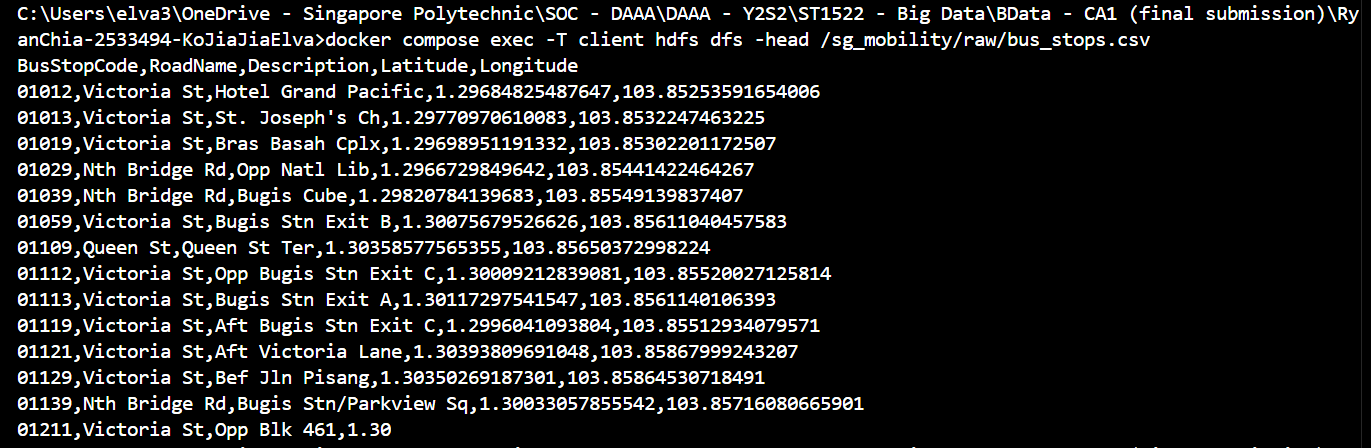

### Recorded Replica Changes

**Before stopping the node** — [full report](../evidence/fault-tolerance-demo/replication-before.txt)

```text
/sg_mobility/raw/bus_stops.csv 357464 bytes, replicated: replication=2, 1 block(s):  OK
0. BP-2088541905-127.0.0.1-1795002543518:blk_1073741825_1001 len=357464 Live_repl=2  [DatanodeInfoWithStorage[172.22.0.6:9866,DS-196b79f9-5cbd-4132-9a46-a85955dc82a4,DISK], DatanodeInfoWithStorage[172.22.0.4:9866,DS-bcac948f-2221-4f82-8fef-e08bec7978e4,DISK]]
```

**During recovery** — [full report](../evidence/fault-tolerance-demo/replication-during.txt)

```text
/sg_mobility/raw/bus_stops.csv 357464 bytes, replicated: replication=2, 1 block(s):  Under replicated BP-2088541905-127.0.0.1-1795002543518:blk_1073741825_1001. Target Replicas is 2 but found 1 live replica(s), 0 decommissioned replica(s), 0 decommissioning replica(s).
0. BP-2088541905-127.0.0.1-1795002543518:blk_1073741825_1001 len=357464 Live_repl=1  [DatanodeInfoWithStorage[172.22.0.6:9866,DS-196b79f9-5cbd-4132-9a46-a85955dc82a4,DISK]]
```

**After re-replication, node still stopped** — [full report](../evidence/fault-tolerance-demo/replication-after.txt)

```text
/sg_mobility/raw/bus_stops.csv 357464 bytes, replicated: replication=2, 1 block(s):  OK
0. BP-2088541905-127.0.0.1-1795002543518:blk_1073741825_1001 len=357464 Live_repl=2  [DatanodeInfoWithStorage[172.22.0.6:9866,DS-196b79f9-5cbd-4132-9a46-a85955dc82a4,DISK], DatanodeInfoWithStorage[172.22.0.5:9866,DS-2c3f2050-9a5d-4a8a-8bc3-67f92ed1d1d0,DISK]]
```

The during report found one live replica on 172.22.0.6. The later report
found two on 172.22.0.6 and 172.22.0.5 while only two DataNodes were live.
The new address shows HDFS created a replacement on datanode1.

A report can say HEALTHY while a block is under-replicated but still readable.
Check the live replica count and under-replication fields, not only the headline.
Failure detection and copying take time; the during state may be brief.

If reproducing the outage, repeat the next check after allowing time for failure
detection and copying. Keep the selected node stopped until two live replicas
appear on the other available nodes. Do not claim recovery before the report
shows it; a new run's timing and replica locations can differ.

In [ ]:
if RUN_FAULT_TEST:
    client("hdfs", "fsck", "/sg_mobility/raw/bus_stops.csv",
           "-files", "-blocks", "-locations", save_as="replication-after.txt")
else:
    print("Live recovery check skipped.")

## 10 Restart the DataNode and Verify Recovery

I restarted the same service with its existing storage, then checked DataNode
registration and all files under /sg_mobility/. The Word report records three
live DataNodes and zero under-replicated, missing or corrupt blocks.

In [ ]:
if RUN_FAULT_TEST:
    run_command(["docker", "compose", "start", TARGET_DATANODE])
    client("hdfs", "dfsadmin", "-report", save_as="dfsadmin-after-restart.txt")
    client("hdfs", "fsck", "/sg_mobility/", "-files", "-blocks", "-locations",
           save_as="replication-after-restart.txt")
else:
    print("Restart not needed: this notebook has not rerun the controlled stop.")

### Recorded Restart Result

[The final saved fsck](../evidence/fault-tolerance-demo/replication-after-restart.txt)
reported a healthy cluster after the restart. The corresponding dfsadmin
screenshot shows three live DataNodes and zero missing, corrupt or
under-replicated blocks.

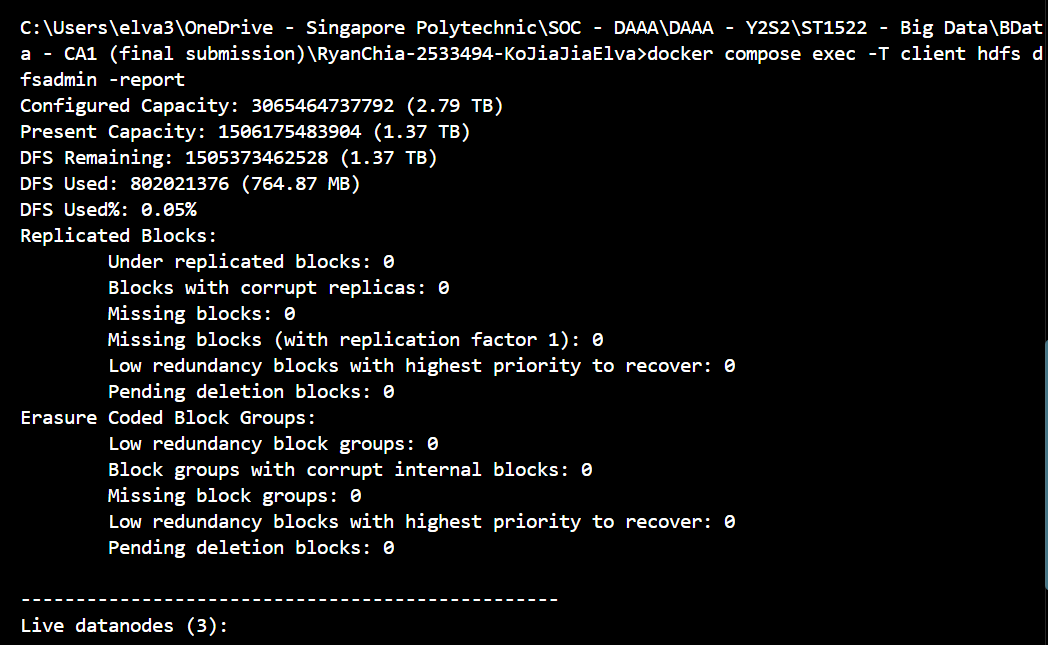

### What the Demonstration Establishes

| Point | Explanation |
|---|---|
| Readability after one replica holder stops | Another DataNode still stores a usable copy |
| Restoring replication | The third node gives HDFS somewhere to place a replacement copy |
| Recovery delay | The NameNode must detect missed heartbeats and schedule copying |
| Storage durability | Persistent mounts preserve data when a container is restarted or recreated; replication adds another block copy |
| Limit | One NameNode has no standby to take over automatically; DataNode replication alone does not provide NameNode high availability |

The test demonstrates one DataNode outage, not recovery from every possible
failure or protection against deleting all stored copies.

## 11 Final HDFS Contents and Provenance

The initial four-file check above preceded preparation. The final project also
uploads canonical CSVs, quarantine records and metadata under /sg_mobility/.
The [data provenance note](../data_provenance.md) explains field mappings,
actual periods, accepted/excluded counts, cadence and missing fields. The
[manifest](../userfiles/metadata/manifest.json) identifies exact local file bytes.

| HDFS folder | Contents |
|---|---|
| /sg_mobility/raw/ | Four original CSVs |
| /sg_mobility/canonical/ | Bus OD, bus stops, rainfall, weather stations and parking |
| /sg_mobility/quarantine/ | Rejected records and duplicate records with reasons |
| /sg_mobility/metadata/ | Student-generated manifest, provenance note and rainfall profile |

Benchmark runs used the same canonical inputs; no separate replicated benchmark
extract was used for conclusions. Any separate benchmark copies belong under
/sg_mobility/benchmark/.

The [HDFS verification report](../evidence/data-preparation/provenance-hdfs-verification.txt)
records **16 successful SHA-256 comparisons** between HDFS contents and local
files, including the uploaded metadata. This confirms matching local/uploaded
bytes. A lecturer-issued manifest was unavailable, so it is not a claim of
verification against lecturer-supplied expected hashes.

In [ ]:
client("hdfs", "dfs", "-ls", "/sg_mobility/canonical", "/sg_mobility/quarantine",
       "/sg_mobility/metadata", save_as="final-hdfs-directories.txt")

## Supporting Documents

- [Configuration justification](../config_justification.md): settings and their effects.
- [Debugging journal](../debugging_journal.md): original and later issues, with controlled tests labelled.
- [Evidence folder guide](../evidence/README.md): current locations and historical path changes.
- [MapReduce analytics](../userfiles/mapreduce/MapReduce_Analytics.md): M1-M4 methods, results and diagrams.

The six screenshots are embedded copies from my Word documentation. The
original Word file is not required to display them. Saved reports remain linked
to the project evidence folders.